In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

In [35]:
df = pd.read_csv("/content/data.csv")

df

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Target,Price_Target
0,40.0,9165.0,55361,2.9,NaN,NaN,495310.0,2091,15.1,Dhaka,Unknown,A,NaN,NaN,S,Male,0,280.32
1,33.0,5522.0,48717,NaN,52868.0,1.0,368695.0,1504,28.3,Chittagong,C,C,Type3,NaN,S,Female,1,314.83
2,42.0,50589.0,64787,3.1,79526.0,2.0,453606.0,2052,22.0,Sylhet,A,C,Type1,NaN,C,Female,0,252.43
3,53.0,61289.0,80106,3.6,107581.0,1.0,359753.0,2075,22.7,Rajshahi,C,B,Type2,NaN,S,Female,0,239.21
4,32.0,1604.0,31872,4.0,89654.0,1.0,228869.0,1248,NaN,Rajshahi,A,C,Type2,NaN,S,Female,0,179.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,31.0,16472.0,50253,3.2,82289.0,4.0,NaN,1832,17.0,Dhaka,A,C,Type1,NaN,C,Female,0,309.92
996,56.0,11596.0,41951,2.7,32733.0,2.0,NaN,1127,17.0,Sylhet,A,C,Type1,Cabin_D,S,Male,0,222.41
997,42.0,NaN,44369,2.6,50537.0,2.0,346644.0,1654,24.7,Rajshahi,C,B,Type2,NaN,S,Female,0,221.89
998,NaN,276.0,52691,3.9,143880.0,4.0,307904.0,1908,Unknown,Rajshahi,B,B,NaN,NaN,Q,Female,0,293.69


# Problem 1:

In [36]:
X = df.drop('Target', axis=1)
y = df['Target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

imputer = SimpleImputer(strategy='median')
imputer.fit(X_train[['Age', 'Salary']])

X_train[['Age', 'Salary']] = imputer.transform(X_train[['Age', 'Salary']])
X_test[['Age', 'Salary']] = imputer.transform(X_test[['Age', 'Salary']])

# Problem 2:

In [37]:
df.isnull().sum()

,0
Age,180
Income,150
Salary,0
Rating,80
Annual_Income,120
Customer_Support_Calls,80
House_Price,100
Square_Feet,0
Temperature,50
City,50


In [38]:
(df.isnull().sum() / len(df) ) * 100

,0
Age,18.0
Income,15.0
Salary,0.0
Rating,8.0
Annual_Income,12.0
Customer_Support_Calls,8.0
House_Price,10.0
Square_Feet,0.0
Temperature,5.0
City,5.0


In [39]:
df.loc[:, (df.isnull().sum() / len(df) ) * 100 > 50]

,Cabin
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
995,NaN
996,Cabin_D
997,NaN
998,NaN


# Problem 3:

In [40]:
df['Temperature'] = np.where(df['Temperature'] == 'Unknown', np.nan,  df['Temperature']).astype(float)

df['Temperature']

,Temperature
0,15.1
1,28.3
2,22.0
3,22.7
4,NaN
...,...
995,17.0
996,17.0
997,24.7
998,NaN


# Problem 4:

In [43]:
imp_const = SimpleImputer(missing_values=np.nan , strategy='constant', fill_value='Missing', add_indicator=True)

imp_const.fit(X_train[['Diagnosis']])

X_train[['Diagnosis', 'diagnosis_missing_indicator']] = imp_const.transform(X_train[['Diagnosis']])
X_test[['Diagnosis', 'diagnosis_missing_indicator']] = imp_const.transform(X_test[['Diagnosis']])

In [44]:
X_train

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Price_Target,diagnosis_missing_indicator
761,36.0,26531.0,51528.0,4.7,73565.0,0.0,323425.0,2133,28.0,Dhaka,B,A,Type1,NaN,S,Male,208.17,False
736,38.0,NaN,65512.0,2.7,87410.0,3.0,NaN,1420,Unknown,Dhaka,A,B,Type1,NaN,Q,Male,270.87,False
965,52.0,46055.0,83595.0,3.8,68592.0,1.0,204930.0,2440,22.8,Rajshahi,A,A,Type1,NaN,S,Female,195.72,False
341,37.0,NaN,76714.0,4.6,119968.0,2.0,436552.0,1981,25.7,Rajshahi,A,B,Missing,NaN,S,Male,169.21,True
20,52.0,37369.0,64006.0,3.4,75867.0,0.0,355872.0,2179,17.2,Dhaka,A,B,Type2,Cabin_B,C,Female,274.51,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
752,23.0,NaN,41314.0,3.5,69528.0,NaN,357707.0,2072,19.7,Dhaka,A,B,Type3,NaN,S,Female,160.49,False
808,35.0,78814.0,72726.0,4.5,74797.0,1.0,386018.0,2138,24.1,Dhaka,B,C,Missing,NaN,S,Female,213.26,True
618,35.0,29765.0,85101.0,3.8,71870.0,1.0,278546.0,2103,17.4,Dhaka,A,B,Missing,NaN,C,Female,299.09,True
941,35.0,10248.0,80122.0,4.4,62788.0,2.0,507777.0,2400,25.7,Khulna,C,B,Type2,Cabin_G,S,Male,228.37,False


# Problem 5:

In [51]:
df = pd.read_csv("/content/data.csv")
X = df.drop('Target', axis=1)
y = df['Target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Age_mean_imputed = SimpleImputer(missing_values=np.nan, strategy='mean')
Age_median_imputed = SimpleImputer(missing_values=np.nan, strategy='median')

Age_mean_imputed.fit(X_train[['Age']])
Age_median_imputed.fit(X_train[['Age']])

X_train['Age_mean_imputed'] = Age_mean_imputed.transform(X_train[['Age']]).ravel()
X_test['Age_mean_imputed'] = Age_mean_imputed.transform(X_test[['Age']]).ravel()

X_train['Age_median_imputed'] = Age_median_imputed.transform(X_train[['Age']]).ravel()
X_test['Age_median_imputed'] = Age_median_imputed.transform(X_test[['Age']]).ravel()

In [53]:
X_train.isnull().sum()

,0
Age,146
Income,121
Salary,0
Rating,66
Annual_Income,101
Customer_Support_Calls,64
House_Price,75
Square_Feet,0
Temperature,38
City,40


<Axes: xlabel='Age_mean_imputed', ylabel='Density'>

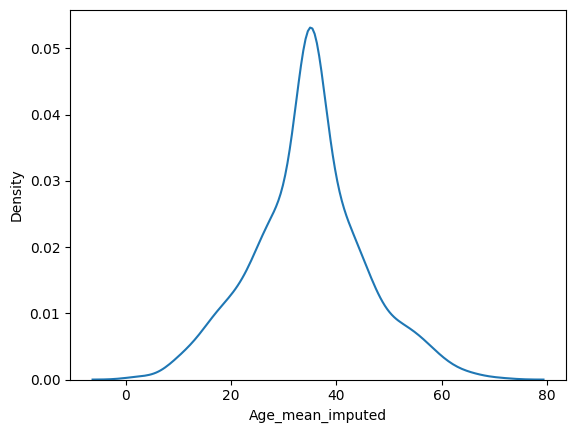

In [47]:
sns.kdeplot(data=X_train, x='Age_mean_imputed')

<Axes: xlabel='Age_median_imputed', ylabel='Density'>

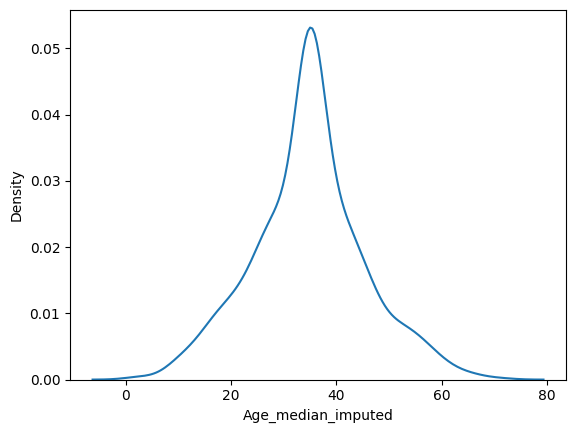

In [48]:
sns.kdeplot(data=X_train, x='Age_median_imputed')

I would Chose the middle one because it's for at the center.

# Problem 6:

1. Income -> Meadian() -> Because it's skewed
2. Rating -> Mean() -> Normally ditributed
3. City -> Mode -> One dominates 40%
4. Diagnosis ->  Constant -> "Missing"
5. Cabin -> Will drop it